# 04 · De las publicaciones a la tabla unificada de TPM

La muestra comprende **161 decisiones de 2010–2025**, con una fila por anuncio. Las fechas de anuncio de TPM **ya están documentadas**. Lo que los CSV de indicadores no informaban era cuándo se publicó cada resultado, distinto del mes que mide. Aquí incorporamos un caso real verificado de IPC y explicamos cómo extenderlo a las ocho series.

Primero mostramos la lógica visualmente; luego importamos, recortamos, exploramos e indexamos cada dataset. La ejecución es local y reproducible desde la raíz o `notebooks/`, con el entorno del proyecto. Los extractos de cuatro boletines INE y sus enlaces quedan conservados en `data/raw/publicaciones_indicadores/`.


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src/processing/data_unificada.py').exists()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.processing.data_unificada import (
    SERIES, cargar, preparar_captura, vincular, exportar
)
from src.processing.figuras_integracion import generar_figuras
reuniones, datasets, inventario = cargar(ROOT)
pd.set_option('display.max_columns', 12)


## 1. Por qué necesitamos las fechas de anuncio

La TPM diaria registra un nivel que se repite mientras no cambie la tasa. Una reunión que mantiene la TPM no produce un salto: por eso **el tramo plano no permite identificar sus reuniones**. Una subida o baja tampoco convierte automáticamente su primera observación diaria en fecha de anuncio. El historial de comunicados identifica los eventos y la serie diaria permite contrastar niveles.


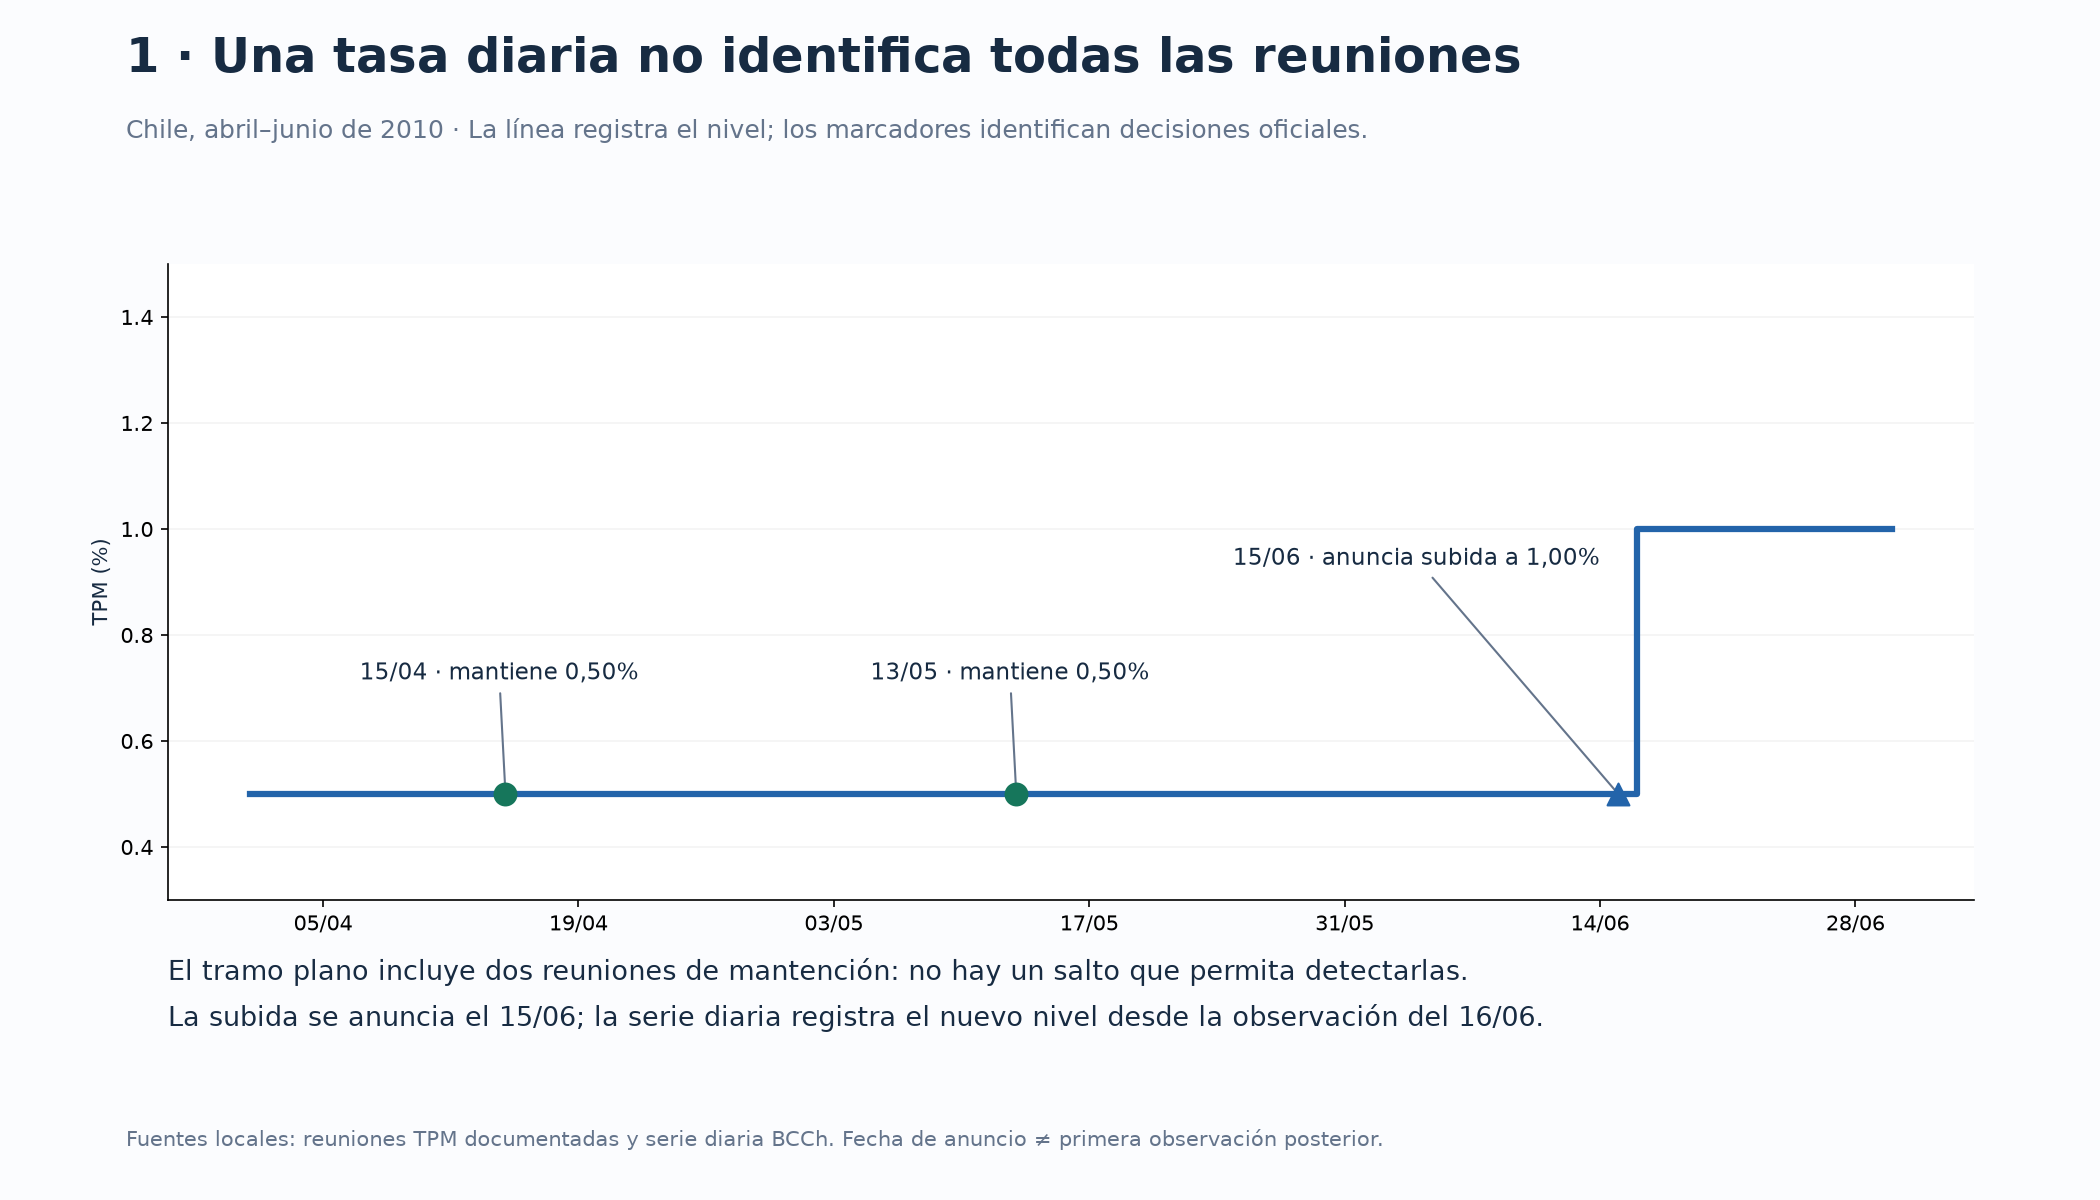

,id_reunion,fecha_decision,fecha_corte,tpm_previa_pct,tpm_posterior_pct,decision
3,RPM_20100415,2010-04-15,2010-04-14,0.5,0.5,mantiene
4,RPM_20100513,2010-05-13,2010-05-12,0.5,0.5,mantiene
5,RPM_20100615,2010-06-15,2010-06-14,0.5,1.0,sube


In [2]:
figuras = generar_figuras(ROOT, reuniones, datasets)
display(Image(filename=str(figuras[0])))
display(reuniones.loc[reuniones.fecha_decision.between('2010-04-01', '2010-06-30'),
    ['id_reunion', 'fecha_decision', 'fecha_corte', 'tpm_previa_pct', 'tpm_posterior_pct', 'decision']])


## 2. El día hábil anterior es el corte de información

Para la decisión del **17/10/2024**, el corte es el **16/10/2024** al cierre, en `America/Santiago`. El IPC de septiembre fue publicado el 08/10 y estaba disponible; el de octubre fue publicado el 08/11 y todavía no existía como información pública. Elegir el IPC del mismo mes de la reunión usando el archivo actual introduciría información futura.

El criterio es **última información publicada hasta el corte**, no que todas las mediciones tengan fecha del día anterior. En cobre puede ser una cotización diaria; en IPC, un resultado de un mes anterior. Los retrasos no son fallas del dataset: son parte de cómo la información llega a quien predice.

Fuentes verificadas: [INE, IPC septiembre (boletín 311)](https://www.ine.gob.cl/docs/default-source/%C3%ADndice-de-precios-al-consumidor/boletines/espa%C3%B1ol/2024/boletin_ipc_septiembre-2024.pdf), [INE, IPC octubre (boletín 312)](https://www.ine.gob.cl/docs/default-source/%C3%ADndice-de-precios-al-consumidor/boletines/espa%C3%B1ol/2024/boletin-ipc-octubre-2024.pdf), [BCCh, comunicado del 17/10/2024](https://www.bcentral.cl/contenido/-/details/comunicado-rpm-octubre-2024). Las otras dos fuentes del ejemplo se conservan en el CSV de extractos.


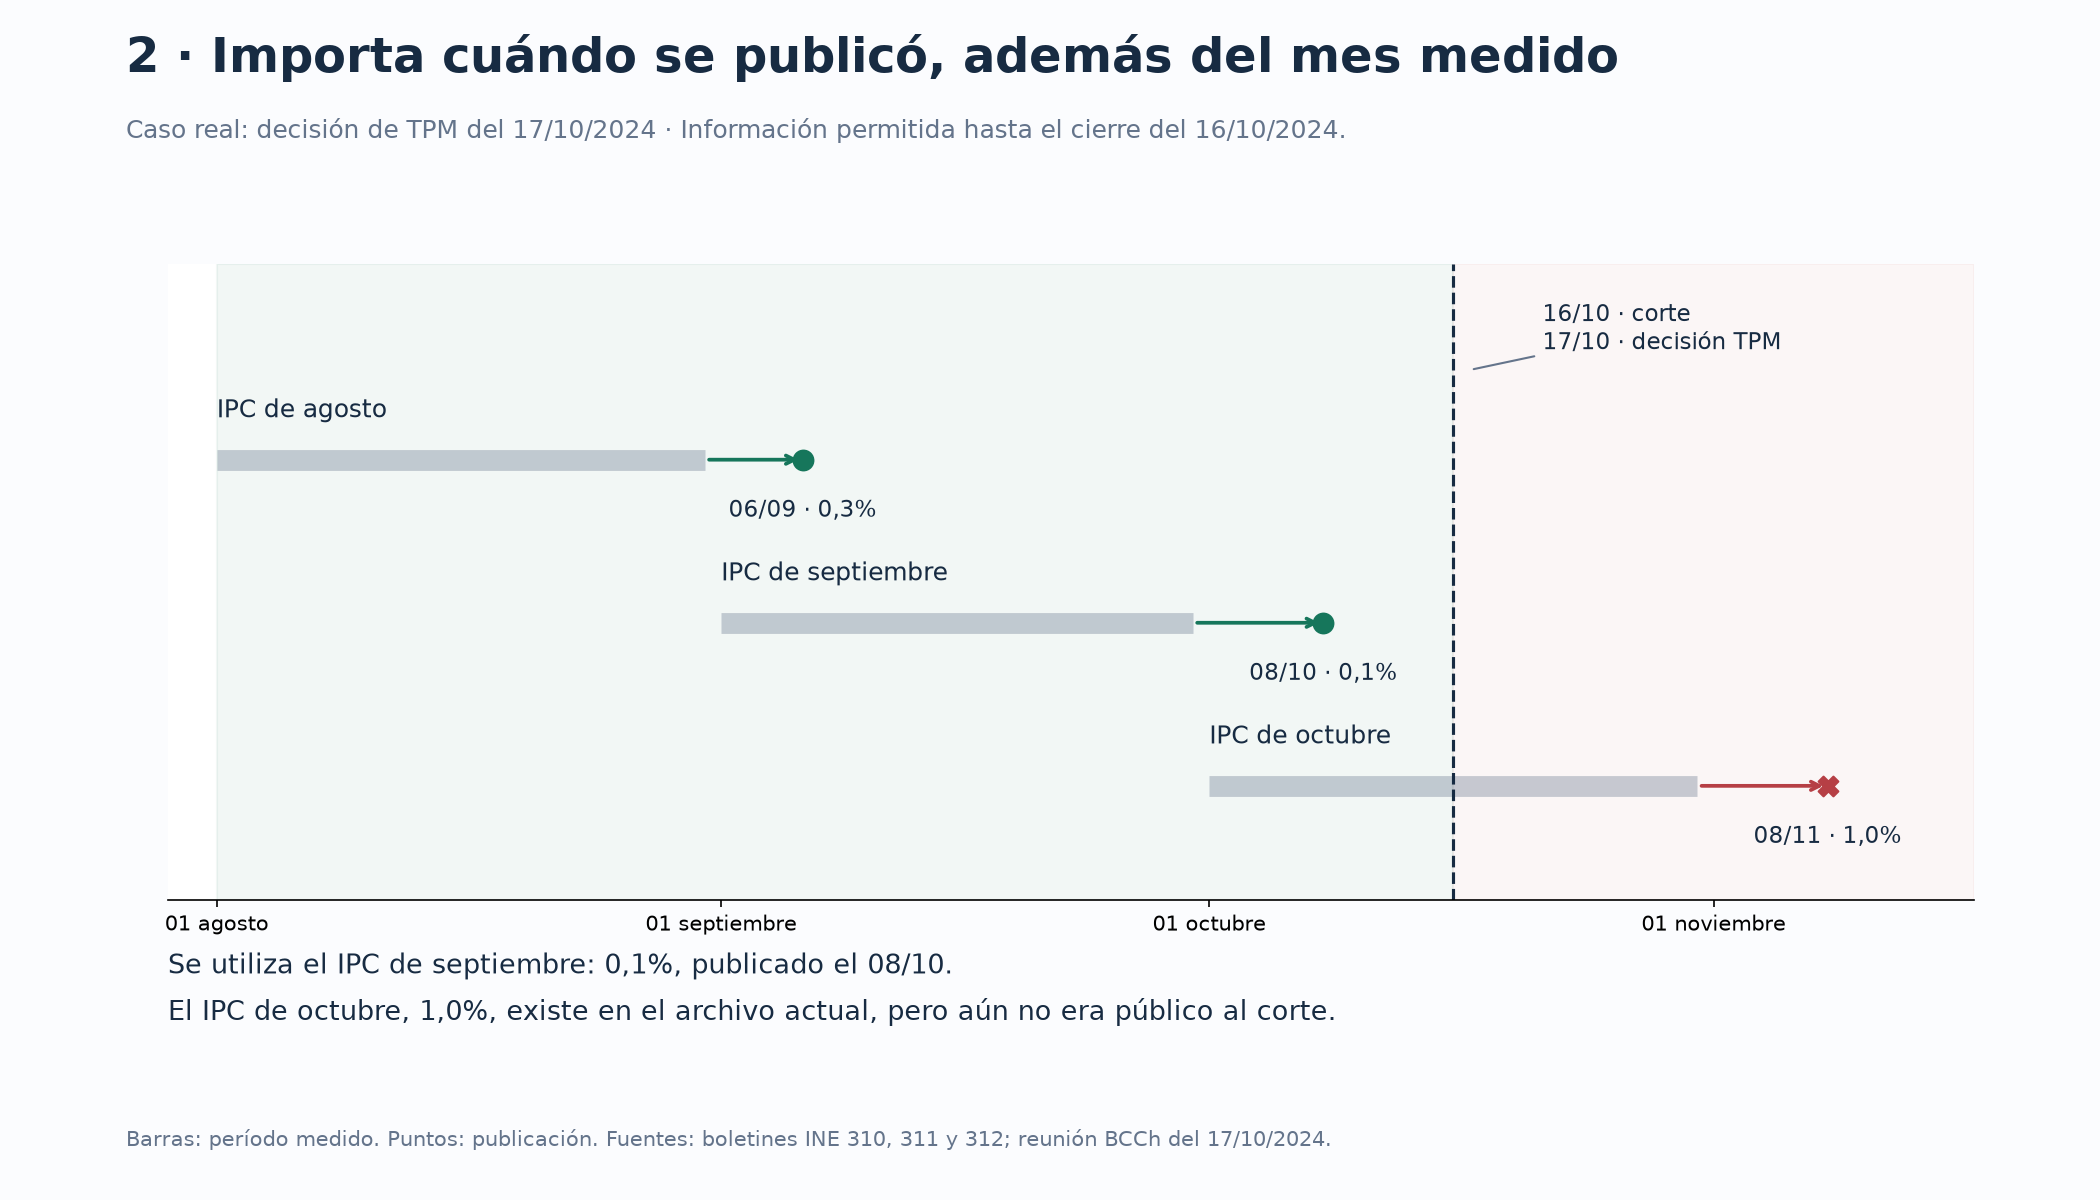

Calendario operativo reconciliado: última fecha TPM diaria estrictamente anterior al anuncio.


In [3]:
display(Image(filename=str(figuras[1])))
diaria = datasets['tpm_bcentral_diaria'][['fecha']].rename(columns={'fecha': 'corte_recalculado'})
control = pd.merge_asof(reuniones.sort_values('fecha_decision'), diaria,
    left_on='fecha_decision', right_on='corte_recalculado', direction='backward', allow_exact_matches=False)
assert control.fecha_corte.eq(control.corte_recalculado).all()
assert reuniones.id_reunion.is_unique
print('Calendario operativo reconciliado: última fecha TPM diaria estrictamente anterior al anuncio.')


El calendario operativo usa fechas presentes en la serie oficial, no una resta de un día ni un supuesto lunes–viernes. Falta contrastarlo con un calendario bancario independiente. Para reuniones de dos días, el corte puede coincidir con el primero: no significa predecir antes del inicio de la sesión. Los calendarios de mercado de cobre y de Chile pueden diferir.


## 3. Indexar y vincular las tablas

`id_reunion = RPM_AAAAMMDD` identifica el anuncio y permanece estable al insertar nuevas filas. `id_observacion = variable_AAAAMMDD` identifica el período medido. La tabla intermedia contiene **un vínculo por reunión y variable**; una medición puede servir a varias reuniones. Por eso no escribimos un único ID de reunión en cada fila original de un indicador.

Los IDs permiten rastrear la relación; la fecha de disponibilidad determina qué observación se elige. Después pivotamos los vínculos para obtener una fila por reunión y una columna por indicador. `decision` es la etiqueta que queremos predecir; se conoce después del corte y nunca entra en los predictores.


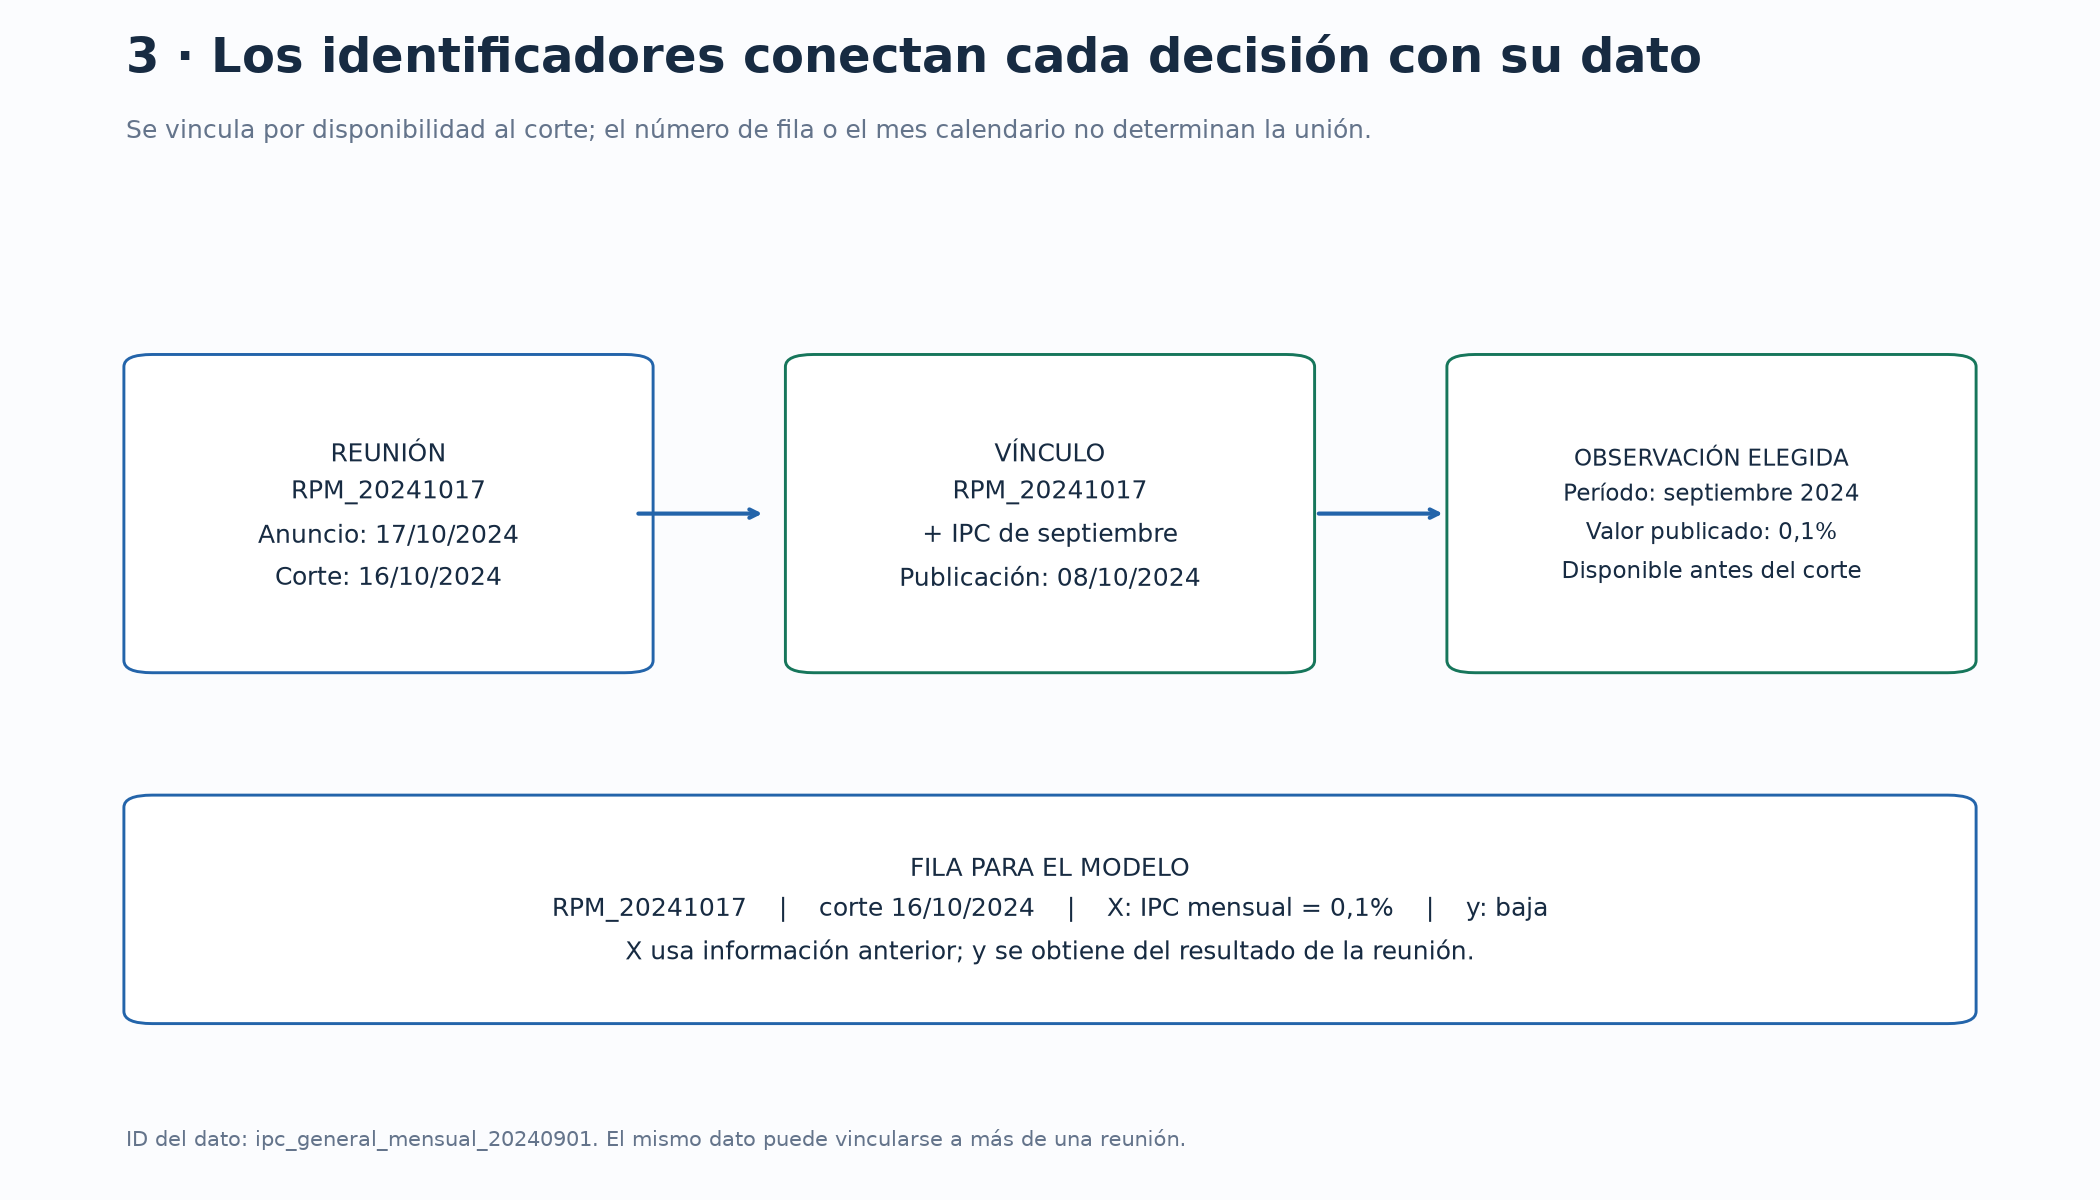

In [4]:
display(Image(filename=str(figuras[2])))


## 4. Recortar la ventana de trabajo

Las vistas principales y la muestra de reuniones quedan en **2010–2025**. Las copias analíticas no incluyen décadas anteriores ni datos posteriores a 2025. Conservamos **solo 2009 como reserva técnica separada**, porque algunas publicaciones disponibles en enero de 2010 describen períodos del año anterior; eliminarlo todo dejaría vacíos artificiales al inicio. La reserva no agrega decisiones de 2009 al entrenamiento. Se revisará su uso al completar los calendarios; no se rellenan faltantes con información futura.

Los archivos originales conservan su cobertura. Las salidas `serie_*_2010_2025.csv` sí quedan recortadas; `antecedentes_2009_*.csv` se exportan aparte.


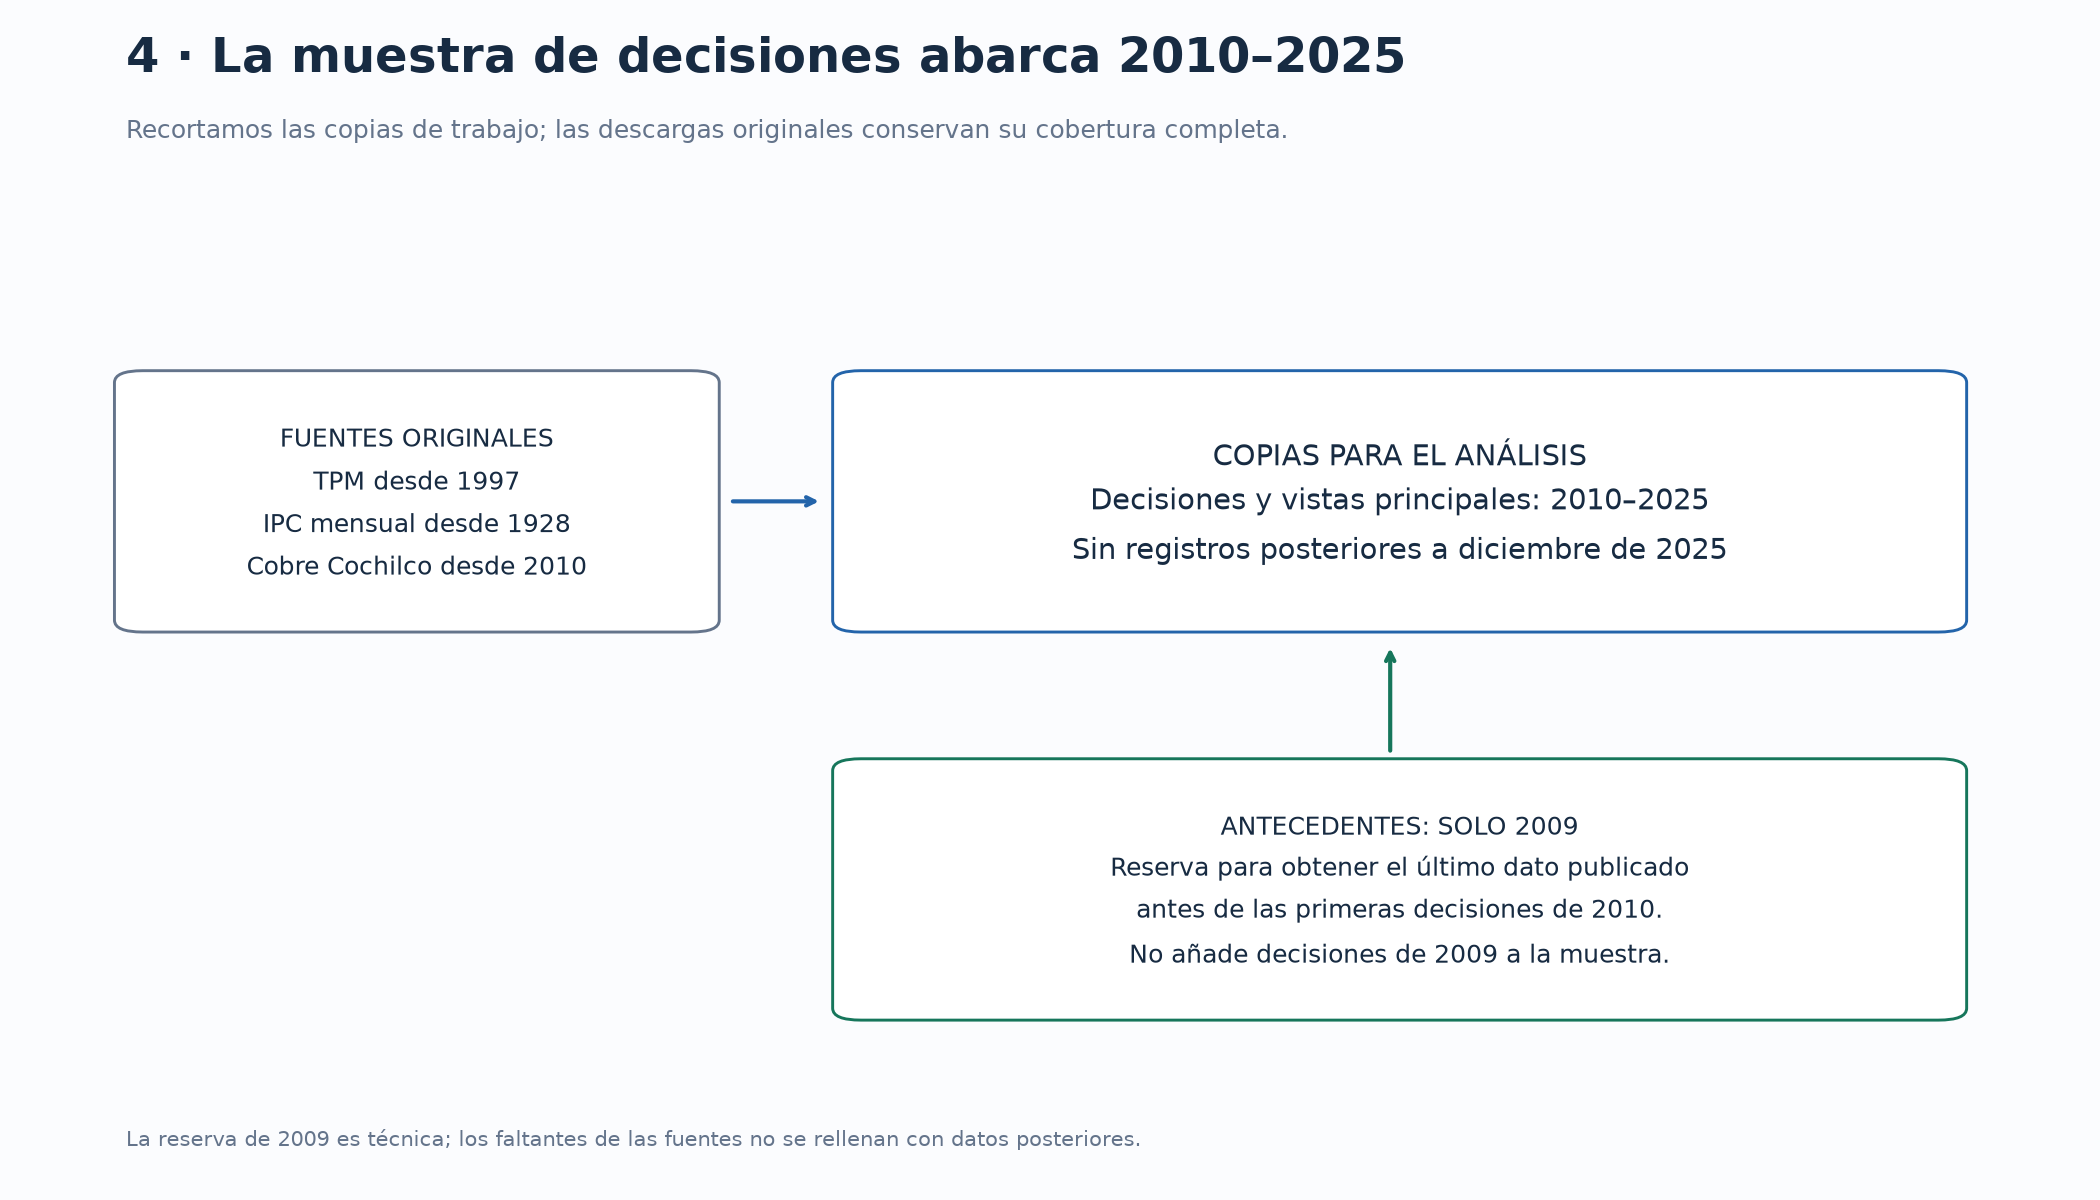

,variable,inicio_original,fin_original,filas_2010_2025,antecedentes_2009
0,tpm_bcentral_diaria,1997-02-07,2026-09-22,3984,250
1,clp_usd,1982-08-09,2026-09-23,3983,250
2,cu_usd_lb,2010-01-04,2025-12-31,4042,0
3,desempleo_total_mensual,2010-03-01,2026-07-01,190,0
4,exp_tpm_mensual_mediana,2001-09-01,2026-09-01,192,12
5,imacec_empalmado_original,1996-01-01,2026-07-01,192,12
6,ipc_general_mensual,1928-03-01,2026-08-01,192,12
7,ipc_general_anual,1929-01-01,2025-01-01,16,1


In [5]:
display(Image(filename=str(figuras[3])))
display(inventario[['variable', 'inicio_original', 'fin_original', 'filas_2010_2025', 'antecedentes_2009']])
assert reuniones.fecha_decision.between('2010-01-01', '2025-12-31').all()
assert all(df.fecha.between('2009-01-01', '2025-12-31').all() for df in datasets.values())


## 5. Importación y exploración individual de las ocho series

Las vistas siguientes solo muestran 2010–2025. `fecha` es el campo original de referencia; no se renombra como publicación sin comprobarlo. Se usa exclusivamente **Cochilco** para cobre; no se añaden como variables las tablas auxiliares ni la alternativa BCCh.


### tpm_bcentral_diaria

TPM vigente; contrastar con tpm_previa_pct, no con el resultado.

Archivo: `tpm_bcentral_diaria_clean.csv`. Frecuencia: diaria. Unidad: %.

Contrastar con TPM previa. El nivel anunciado, el posterior y la variación son datos del resultado y se excluyen de X.

In [6]:
serie = datasets['tpm_bcentral_diaria']
principal = serie.loc[serie.en_ventana_2010_2025]
display(principal.head(4))
print('Filas 2010–2025:', len(principal), '| Reserva 2009:', int((~serie.en_ventana_2010_2025).sum()),
      '| Duplicados:', serie.fecha.duplicated().sum(), '| Nulos:', serie['tpm_bcentral_diaria'].isna().sum())


,id_observacion,fecha,tpm_bcentral_diaria,en_ventana_2010_2025
250,tpm_bcentral_diaria_20100104,2010-01-04,0.5,True
251,tpm_bcentral_diaria_20100105,2010-01-05,0.5,True
252,tpm_bcentral_diaria_20100106,2010-01-06,0.5,True
253,tpm_bcentral_diaria_20100107,2010-01-07,0.5,True


Filas 2010–2025: 3984 | Reserva 2009: 250 | Duplicados: 0 | Nulos: 0


### clp_usd

Dólar observado; operaciones del día bancario previo a su publicación.

Archivo: `clp_usd_clean.csv`. Frecuencia: diaria. Unidad: CLP/USD.

El dólar observado describe operaciones del día bancario previo a su publicación. Distinguir ambas fechas; no aplicar un segundo desfase automático.

In [7]:
serie = datasets['clp_usd']
principal = serie.loc[serie.en_ventana_2010_2025]
display(principal.head(4))
print('Filas 2010–2025:', len(principal), '| Reserva 2009:', int((~serie.en_ventana_2010_2025).sum()),
      '| Duplicados:', serie.fecha.duplicated().sum(), '| Nulos:', serie['clp_usd'].isna().sum())


,id_observacion,fecha,clp_usd,en_ventana_2010_2025
250,clp_usd_20100104,2010-01-04,507.10,True
251,clp_usd_20100105,2010-01-05,505.70,True
252,clp_usd_20100106,2010-01-06,504.22,True
253,clp_usd_20100107,2010-01-07,497.93,True


Filas 2010–2025: 3983 | Reserva 2009: 250 | Duplicados: 0 | Nulos: 0


### cu_usd_lb

Cobre spot BML/LME de Cochilco; fuente única 2010–2025.

Archivo: `cobre_cochilco_diario_2010_2025.csv`. Frecuencia: diaria. Unidad: USD/libra.

Sin interpolación. Cuando el mercado no observa el día de corte, usar la última cotización anterior disponible e informar su antigüedad.

In [8]:
serie = datasets['cu_usd_lb']
principal = serie.loc[serie.en_ventana_2010_2025]
display(principal.head(4))
print('Filas 2010–2025:', len(principal), '| Reserva 2009:', int((~serie.en_ventana_2010_2025).sum()),
      '| Duplicados:', serie.fecha.duplicated().sum(), '| Nulos:', serie['cu_usd_lb'].isna().sum())


,id_observacion,fecha,cu_usd_lb,fuente,mercado,unidad,archivo_origen,en_ventana_2010_2025
0,cu_usd_lb_20100104,2010-01-04,3.3856,Cochilco,BML/LME spot,USD/libra,cochilco_cobre_bml_2010_2013.xls,True
1,cu_usd_lb_20100105,2010-01-05,3.3729,Cochilco,BML/LME spot,USD/libra,cochilco_cobre_bml_2010_2013.xls,True
2,cu_usd_lb_20100106,2010-01-06,3.4416,Cochilco,BML/LME spot,USD/libra,cochilco_cobre_bml_2010_2013.xls,True
3,cu_usd_lb_20100107,2010-01-07,3.4446,Cochilco,BML/LME spot,USD/libra,cochilco_cobre_bml_2010_2013.xls,True


Filas 2010–2025: 4042 | Reserva 2009: 0 | Duplicados: 0 | Nulos: 0


### desempleo_total_mensual

Desocupación INE, trimestre móvil; validar mes de referencia y revisiones.

Archivo: `desempleo_total_mensual_clean.csv`. Frecuencia: mensual. Unidad: %.

Son estimaciones de trimestres móviles actualizadas mensualmente. La serie comienza en marzo de 2010; las primeras reuniones carecen de esta entrada. Revisar mes final y recalibraciones.

In [9]:
serie = datasets['desempleo_total_mensual']
principal = serie.loc[serie.en_ventana_2010_2025]
display(principal.head(4))
print('Filas 2010–2025:', len(principal), '| Reserva 2009:', int((~serie.en_ventana_2010_2025).sum()),
      '| Duplicados:', serie.fecha.duplicated().sum(), '| Nulos:', serie['desempleo_total_mensual'].isna().sum())


,id_observacion,fecha,desempleo_total_mensual,en_ventana_2010_2025
0,desempleo_total_mensual_20100301,2010-03-01,9.227598,True
1,desempleo_total_mensual_20100401,2010-04-01,8.836054,True
2,desempleo_total_mensual_20100501,2010-05-01,9.087731,True
3,desempleo_total_mensual_20100601,2010-06-01,8.656064,True


Filas 2010–2025: 190 | Reserva 2009: 0 | Duplicados: 0 | Nulos: 0


### exp_tpm_mensual_mediana

EEE: mediana de TPM esperada en el mes; verificar publicación de cada encuesta.

Archivo: `exp_tpm_mensual_mediana_clean.csv`. Frecuencia: mensual. Unidad: %.

La fecha al primer día del mes codifica el período; no prueba disponibilidad. Conservar el horizonte esperado y la fecha efectiva de cada encuesta.

In [10]:
serie = datasets['exp_tpm_mensual_mediana']
principal = serie.loc[serie.en_ventana_2010_2025]
display(principal.head(4))
print('Filas 2010–2025:', len(principal), '| Reserva 2009:', int((~serie.en_ventana_2010_2025).sum()),
      '| Duplicados:', serie.fecha.duplicated().sum(), '| Nulos:', serie['exp_tpm_mensual_mediana'].isna().sum())


,id_observacion,fecha,exp_tpm_mensual_mediana,en_ventana_2010_2025
12,exp_tpm_mensual_mediana_20100101,2010-01-01,0.5,True
13,exp_tpm_mensual_mediana_20100201,2010-02-01,0.5,True
14,exp_tpm_mensual_mediana_20100301,2010-03-01,0.5,True
15,exp_tpm_mensual_mediana_20100401,2010-04-01,0.5,True


Filas 2010–2025: 192 | Reserva 2009: 12 | Duplicados: 0 | Nulos: 0


### imacec_empalmado_original

IMACEC original empalmado: nivel, no crecimiento; sujeto a revisiones.

Archivo: `imacec_empalmado_original_clean.csv`. Frecuencia: mensual. Unidad: 2018=100.

Es un índice original empalmado, no crecimiento. Puede contener revisiones posteriores. La fecha inicial de publicación no autoriza usar el valor revisado de hoy. El calendario cambió en 2019.

In [11]:
serie = datasets['imacec_empalmado_original']
principal = serie.loc[serie.en_ventana_2010_2025]
display(principal.head(4))
print('Filas 2010–2025:', len(principal), '| Reserva 2009:', int((~serie.en_ventana_2010_2025).sum()),
      '| Duplicados:', serie.fecha.duplicated().sum(), '| Nulos:', serie['imacec_empalmado_original'].isna().sum())


,id_observacion,fecha,imacec_empalmado_original,en_ventana_2010_2025
12,imacec_empalmado_original_20100101,2010-01-01,72.478647,True
13,imacec_empalmado_original_20100201,2010-02-01,69.784256,True
14,imacec_empalmado_original_20100301,2010-03-01,75.714061,True
15,imacec_empalmado_original_20100401,2010-04-01,77.836154,True


Filas 2010–2025: 192 | Reserva 2009: 12 | Duplicados: 0 | Nulos: 0


### ipc_general_mensual

Variación mensual del IPC; no es el nivel del índice.

Archivo: `ipc_general_mensual_clean.csv`. Frecuencia: mensual. Unidad: %.

Es variación mensual, no nivel del índice. El mes de referencia y su publicación en el siguiente mes son distintos, como muestra el ejemplo real.

In [12]:
serie = datasets['ipc_general_mensual']
principal = serie.loc[serie.en_ventana_2010_2025]
display(principal.head(4))
print('Filas 2010–2025:', len(principal), '| Reserva 2009:', int((~serie.en_ventana_2010_2025).sum()),
      '| Duplicados:', serie.fecha.duplicated().sum(), '| Nulos:', serie['ipc_general_mensual'].isna().sum())


,id_observacion,fecha,ipc_general_mensual,en_ventana_2010_2025
12,ipc_general_mensual_20100101,2010-01-01,0.5,True
13,ipc_general_mensual_20100201,2010-02-01,0.3,True
14,ipc_general_mensual_20100301,2010-03-01,0.1,True
15,ipc_general_mensual_20100401,2010-04-01,0.5,True


Filas 2010–2025: 192 | Reserva 2009: 12 | Duplicados: 0 | Nulos: 0


### ipc_general_anual

Variación anual histórica de diciembre: NO es inflación interanual mensual.

Archivo: `ipc_general_anual_clean.csv`. Frecuencia: anual. Unidad: %.

Es variación histórica anual de diciembre, codificada en enero; no inflación interanual mensual. Se importa por estar disponible, pero su pertinencia como predictor debe revisarse.

In [13]:
serie = datasets['ipc_general_anual']
principal = serie.loc[serie.en_ventana_2010_2025]
display(principal.head(4))
print('Filas 2010–2025:', len(principal), '| Reserva 2009:', int((~serie.en_ventana_2010_2025).sum()),
      '| Duplicados:', serie.fecha.duplicated().sum(), '| Nulos:', serie['ipc_general_anual'].isna().sum())


,id_observacion,fecha,ipc_general_anual,en_ventana_2010_2025
1,ipc_general_anual_20100101,2010-01-01,2.97,True
2,ipc_general_anual_20110101,2011-01-01,4.44,True
3,ipc_general_anual_20120101,2012-01-01,1.49,True
4,ipc_general_anual_20130101,2013-01-01,3.00,True


Filas 2010–2025: 16 | Reserva 2009: 1 | Duplicados: 0 | Nulos: 0


## 6. Incorporar las fechas de publicación: ejemplo ya documentado

Aquí corregimos la falta de fechas de publicación **para el caso ilustrado**, usando cuatro boletines consecutivos: IPC de julio, agosto, septiembre y octubre de 2024. Los extractos conservan período, fecha efectiva, valor publicado, enlace y página. No hace falta que cada fila se documente a mano: se pueden capturar calendarios y boletines en bloque, siempre contrastando fuentes y versiones.

La captura editable se conserva al reejecutar; solo se eliminan filas vacías fuera de la ventana y se incorporan los ejemplos donde aún no hay evidencia. Para completar otras fechas, añadir `fecha_disponible`, `valor_publicado`, `fuente_publicacion` y `evidencia_version`. `valor_descargado` solo ayuda al contraste. Para revisiones, añadir versiones con el mismo ID y otra fecha.

**El ejemplo no completa aún las ocho series de 2010–2025.** La cobertura del calendario se declara en `cobertura_ejemplo.csv`: 08/08–08/11/2024 para IPC mensual. Fuera de ese intervalo se mantienen pendientes; no se arrastra la última publicación del ejemplo a todas las reuniones de 2025.


In [14]:
publicaciones, cobertura = preparar_captura(ROOT, datasets)
display(publicaciones.loc[publicaciones.fecha_disponible.notna()])
display(cobertura)
print('Registros de captura:', len(publicaciones))


,id_observacion,variable,fecha_referencia,valor_descargado,fecha_disponible,valor_publicado,fuente_publicacion,evidencia_version,nota
13293,ipc_general_mensual_20240701,ipc_general_mensual,2024-07-01,0.7,2024-08-08,0.7,https://www.ine.gob.cl/docs/default-source/%C3...,Boletín INE edición 309 página 1: fecha y vari...,Consulta 2026-10-17; extracto de hechos públicos
13294,ipc_general_mensual_20240801,ipc_general_mensual,2024-08-01,0.3,2024-09-06,0.3,https://www.ine.gob.cl/docs/default-source/%C3...,Boletín INE edición 310 página 1: fecha y vari...,Consulta 2026-10-17; extracto de hechos públicos
13295,ipc_general_mensual_20240901,ipc_general_mensual,2024-09-01,0.1,2024-10-08,0.1,https://www.ine.gob.cl/docs/default-source/%C3...,Boletín INE edición 311 página 1: fecha y vari...,Consulta 2026-10-17; extracto de hechos públicos
13296,ipc_general_mensual_20241001,ipc_general_mensual,2024-10-01,1.0,2024-11-08,1.0,https://www.ine.gob.cl/docs/default-source/%C3...,Boletín INE edición 312 página 1: fecha y vari...,Consulta 2026-10-17; extracto de hechos públicos


,variable,inicio,fin,nota
0,ipc_general_mensual,2024-08-08,2024-11-08,Ejemplo acotado: cuatro boletines mensuales co...


Registros de captura: 13328


## 7. Asignación por disponibilidad y revisión de vínculos

Se consideran publicaciones con `fecha_disponible <= fecha_corte`. Entre ellas se selecciona el período de referencia más reciente y su última versión disponible al corte. Una revisión tardía de un período antiguo no desplaza un período más reciente. No se usa el dato más cercano en ambas direcciones, desplazamientos de filas ni una unión exacta por mes.

`candidato_*` es la selección ingenua por fecha de referencia: permite ver el riesgo, pero **no es un predictor validado**. Los campos `valor` y `fecha_disponible` contienen la selección respaldada en el intervalo documentado. No se fija aún una tolerancia universal de antigüedad: se revisará por variable.


In [15]:
vinculos, unificada = vincular(reuniones, datasets, publicaciones, cobertura)
caso = vinculos.loc[vinculos.id_reunion.eq('RPM_20241017') & vinculos.variable.eq('ipc_general_mensual')]
display(caso[['id_reunion', 'fecha_corte', 'candidato_fecha', 'candidato_valor',
              'id_observacion', 'fecha_referencia', 'fecha_disponible', 'valor']])
assert caso.iloc[0].id_observacion == 'ipc_general_mensual_20240901'
assert float(caso.iloc[0].valor) == 0.1
assert float(caso.iloc[0].candidato_valor) == 1.0
print('Unión por referencia: octubre (1,0%). Unión por publicación: septiembre (0,1%).')
for variable, grupo in vinculos.groupby('variable', sort=False):
    print(variable)
    display(grupo[['id_reunion', 'fecha_corte', 'candidato_fecha', 'candidato_valor',
                   'fecha_disponible', 'valor', 'estado']].head(3))


,id_reunion,fecha_corte,candidato_fecha,candidato_valor,id_observacion,fecha_referencia,fecha_disponible,valor
1214,RPM_20241017,2024-10-16,2024-10-01,1.0,ipc_general_mensual_20240901,2024-09-01,2024-10-08,0.1


Unión por referencia: octubre (1,0%). Unión por publicación: septiembre (0,1%).
tpm_bcentral_diaria


,id_reunion,fecha_corte,candidato_fecha,candidato_valor,fecha_disponible,valor,estado
0,RPM_20100114,2010-01-13,2010-01-13,0.5,NaT,<NA>,pendiente_evidencia
8,RPM_20100211,2010-02-10,2010-02-10,0.5,NaT,<NA>,pendiente_evidencia
16,RPM_20100318,2010-03-17,2010-03-17,0.5,NaT,<NA>,pendiente_evidencia


clp_usd


,id_reunion,fecha_corte,candidato_fecha,candidato_valor,fecha_disponible,valor,estado
1,RPM_20100114,2010-01-13,2010-01-13,491.16,NaT,<NA>,pendiente_evidencia
9,RPM_20100211,2010-02-10,2010-02-10,541.23,NaT,<NA>,pendiente_evidencia
17,RPM_20100318,2010-03-17,2010-03-17,521.87,NaT,<NA>,pendiente_evidencia


cu_usd_lb


... (7 outputs left out)

ipc_general_mensual


,id_reunion,fecha_corte,candidato_fecha,candidato_valor,fecha_disponible,valor,estado
6,RPM_20100114,2010-01-13,2010-01-01,0.5,NaT,<NA>,pendiente_evidencia
14,RPM_20100211,2010-02-10,2010-02-01,0.3,NaT,<NA>,pendiente_evidencia
22,RPM_20100318,2010-03-17,2010-03-01,0.1,NaT,<NA>,pendiente_evidencia


ipc_general_anual


,id_reunion,fecha_corte,candidato_fecha,candidato_valor,fecha_disponible,valor,estado
7,RPM_20100114,2010-01-13,2010-01-01,2.97,NaT,<NA>,pendiente_evidencia
15,RPM_20100211,2010-02-10,2010-01-01,2.97,NaT,<NA>,pendiente_evidencia
23,RPM_20100318,2010-03-17,2010-01-01,2.97,NaT,<NA>,pendiente_evidencia


## 8. Controles, cobertura y exportación

La tabla preserva las 161 decisiones. Los vacíos distinguen tareas de documentación pendientes de la disponibilidad real de los indicadores; no significan que nunca se publicaran. `lista_para_modelo` exige ocho valores y calendarios cubiertos; no reemplaza la auditoría de fuentes ni la selección de variables. IDs, fechas y campos del resultado no entran automáticamente al modelo.

La fecha de la reunión extraordinaria de marzo de 2020 se conoce retrospectivamente; decidir su evaluación separada antes de entrenar. Mantener una separación cronológica entrenamiento/prueba no elimina por sí sola una fuga causada por predictores publicados después del corte.


In [16]:
resumen = vinculos.groupby('variable', sort=False).agg(
    reuniones=('id_reunion', 'size'), candidatos=('candidato_id', 'count'),
    candidatos_exactos=('candidato_en_fecha_corte', 'sum'),
    valores_documentados=('valor', 'count'),
    maxima_antiguedad_dias=('dias_desde_publicacion', 'max'))
display(resumen)
assert len(vinculos) == len(reuniones) * len(SERIES)
assert not vinculos.duplicated(['id_reunion', 'variable']).any()
documentados = vinculos.loc[vinculos.valor.notna()]
assert documentados.fecha_disponible.le(documentados.fecha_corte).all()
assert documentados.calendario_documentado.all()
assert vinculos.fecha_corte.lt(vinculos.fecha_decision).all()
assert not {'tpm_posterior_pct', 'variacion_pb', 'tpm_anunciada_verificada_pct'} & set(unificada)
assert vinculos.loc[vinculos.fecha_corte.gt('2024-11-08'), 'valor'].isna().all()
comparacion = vinculos.loc[vinculos.variable.eq('tpm_bcentral_diaria')].merge(
    reuniones[['id_reunion', 'tpm_previa_pct']], on='id_reunion', validate='one_to_one')
assert comparacion.candidato_valor.eq(comparacion.tpm_previa_pct).all()
print('Controles temporales, cobertura, cardinalidad y TPM previa: OK')


,reuniones,candidatos,candidatos_exactos,valores_documentados,maxima_antiguedad_dias
variable,,,,,
tpm_bcentral_diaria,161,161,161,0,NaN
clp_usd,161,161,161,0,NaN
cu_usd_lb,161,161,158,0,NaN
desempleo_total_mensual,161,159,1,0,NaN
exp_tpm_mensual_mediana,161,161,1,0,NaN
imacec_empalmado_original,161,161,1,0,NaN
ipc_general_mensual,161,161,1,2,25.0
ipc_general_anual,161,161,0,0,NaN


Controles temporales, cobertura, cardinalidad y TPM previa: OK


In [17]:
vinculos, unificada = exportar(ROOT, reuniones, datasets, publicaciones, cobertura)
salida = ROOT / 'data/processed/unificada'
inventario.to_csv(salida / 'inventario_series.csv', index=False, date_format='%Y-%m-%d')
resumen.to_csv(salida / 'cobertura_por_variable.csv')
display(unificada.loc[unificada.id_reunion.eq('RPM_20241017')])
print('Reuniones:', len(unificada), '| Con ocho valores y calendarios documentados:', int(unificada.lista_para_modelo.sum()))
print('Salidas:', salida.relative_to(ROOT))
print('Series recortadas: serie_*_2010_2025.csv. Antecedentes separados: antecedentes_2009_*.csv.')


,id_reunion,fecha_decision,fecha_corte,tipo_reunion,decision,clp_usd,...,imacec_empalmado_original,ipc_general_anual,ipc_general_mensual,tpm_bcentral_diaria,n_variables_disponibles,lista_para_modelo
151,RPM_20241017,2024-10-17,2024-10-16,ordinaria,baja,<NA>,...,<NA>,<NA>,0.1,<NA>,1,False


Reuniones: 161 | Con ocho valores y calendarios documentados: 0
Salidas: data\processed\unificada
Series recortadas: serie_*_2010_2025.csv. Antecedentes separados: antecedentes_2009_*.csv.


### Pendientes para completar la tabla del modelo

El mecanismo de integración y el caso real de IPC quedan comprobados. Sigue la reconstrucción de publicaciones para las ocho variables durante 2010–2025, incluyendo versiones históricas de series revisables. No basta aplicar a todo el período un calendario actual: por ejemplo, [BCCh anunció un cambio en la publicación del IMACEC en 2019](https://www.bcentral.cl/contenido/-/details/imacec-junio-2019-6). Las [versiones de calibración ENE](https://bancodatosene.ine.cl/) también requieren atención.

Al completar esa información se revisarán la pertinencia del IPC anual, la antigüedad admisible de cada indicador y el calendario bancario independiente. La tabla de entrenamiento usará los valores que se conocían en cada corte, aunque hoy exista información más reciente.
